Loading MNIST...
Sampled 20000 images – shape: (20000, 784)
Applying PCA (50 components)...
Explained variance ratio (first 50): 0.825
K-Means clustering...
Building KNN graph for Spectral...
Eigen decomposition...
K-Means on spectral embedding...

K-Means     ARI = 0.3817
Spectral    ARI = 0.6217


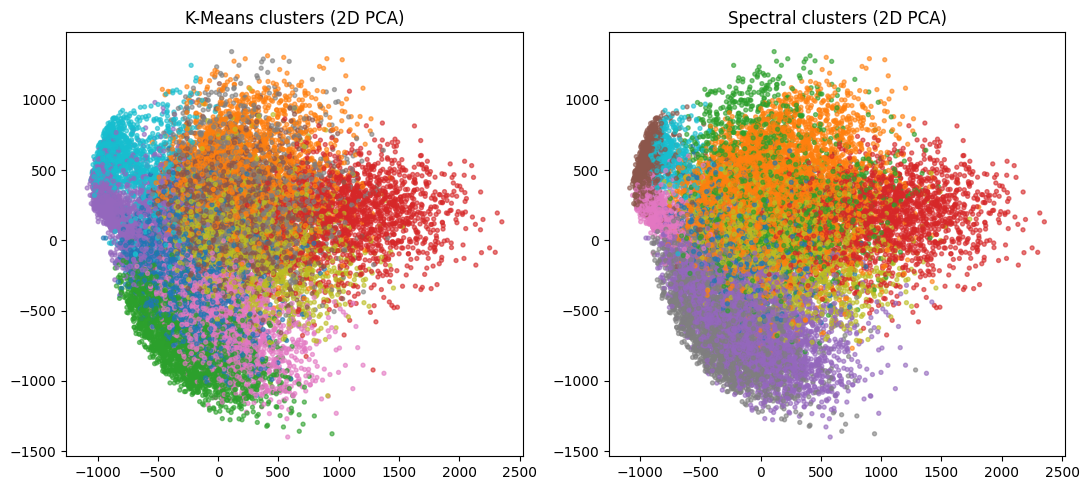

In [1]:
# Install if needed
# !pip install scikit-learn numpy matplotlib

from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import kneighbors_graph
import numpy as np
import matplotlib.pyplot as plt

# ────────────────────────────────────────────────
# 1. Load & sample MNIST
# ────────────────────────────────────────────────
print("Loading MNIST...")
X_all, y_all = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False, parser='auto')

# Sample 20,000 images
np.random.seed(42)
idx = np.random.choice(len(X_all), 20000, replace=False)
X = X_all[idx]
y = y_all[idx].astype(int)

print(f"Sampled {X.shape[0]} images – shape: {X.shape}")

# ────────────────────────────────────────────────
# 2. Dimensionality reduction (very important!)
# ────────────────────────────────────────────────
print("Applying PCA (50 components)...")
pca = PCA(n_components=50)
X_pca = pca.fit_transform(X)
print(f"Explained variance ratio (first 50): {sum(pca.explained_variance_ratio_):.3f}")

# ────────────────────────────────────────────────
# 3. K-Means
# ────────────────────────────────────────────────
print("K-Means clustering...")
km = KMeans(n_clusters=10, random_state=42, n_init=10)
labels_km = km.fit_predict(X_pca)
ari_km = adjusted_rand_score(y, labels_km)

# ────────────────────────────────────────────────
# 4. Spectral Clustering with KNN graph
# ────────────────────────────────────────────────
print("Building KNN graph for Spectral...")
connectivity = kneighbors_graph(X_pca, n_neighbors=15, include_self=False, mode='connectivity')
connectivity = 0.5 * (connectivity + connectivity.T)  # symmetrize

W = connectivity.toarray()
D = np.diag(np.sum(W, axis=1))
L = D - W

print("Eigen decomposition...")
eigvals, eigvecs = np.linalg.eigh(L)
idx_sort = np.argsort(eigvals)
embedding = eigvecs[:, idx_sort[1:11]]   # skip 0, take next 10

print("K-Means on spectral embedding...")
km_spec = KMeans(n_clusters=10, random_state=42, n_init=10)
labels_spec = km_spec.fit_predict(embedding)
ari_spec = adjusted_rand_score(y, labels_spec)

# ────────────────────────────────────────────────
# 5. Print results
# ────────────────────────────────────────────────
print("\n" + "="*60)
print(f"K-Means     ARI = {ari_km:.4f}")
print(f"Spectral    ARI = {ari_spec:.4f}")
print("="*60)

# ────────────────────────────────────────────────
# 6. 2D visualization (for report)
# ────────────────────────────────────────────────
pca2 = PCA(n_components=2)
X_2d = pca2.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].scatter(X_2d[:,0], X_2d[:,1], c=labels_km, s=8, cmap='tab10', alpha=0.6)
axes[0].set_title("K-Means clusters (2D PCA)")

axes[1].scatter(X_2d[:,0], X_2d[:,1], c=labels_spec, s=8, cmap='tab10', alpha=0.6)
axes[1].set_title("Spectral clusters (2D PCA)")

plt.tight_layout()
plt.show()